# Week 7 - Text and Multimodal AI
**Introduction to Applied AI | Project 2: Deep Learning Applications | Lab 7 (individual)**
Muhammad Raheel Ijaz | Department of Electronics, Quaid-i-Azam University

**Domain:** crop disease from leaf images (PlantVillage), carried over from Week 6.
**Runs locally in Jupyter** (not Kaggle). Start Jupyter from the project folder so that `data/` and `week6_model.pt` are found.

Every part ends with a **Write it** cell. These cells are code cells that print Markdown, so every number in them comes from *your own run*. Read the judgement sentences and reword them in your own words before you submit.

## Part 0 - Setup, paths and imports

In [1]:
import re, json, glob, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
warnings.filterwarnings("ignore")
random.seed(42); np.random.seed(42)

# ---- paths (Jupyter must be started from the project folder) ----
PROJECT = Path.cwd()
DATA    = PROJECT / "data"
SMS_CSV = DATA / "spam.csv"                       # Kaggle "SMS Spam Collection Dataset"
W6_PATH = PROJECT / "models" / "week6_model.pt"   # your Week 6 checkpoint
PV_ROOT = DATA / "plantvillage dataset" / "color" # Week 6 image folders
IMG     = PROJECT / "images"                      # figures go here, like Weeks 5 and 6
IMG.mkdir(exist_ok=True)
print("Project folder :", PROJECT)
print("SMS csv        :", SMS_CSV, "->", "found" if SMS_CSV.exists() else "NOT found (loader will try a download)")
print("Week 6 model   :", W6_PATH, "->", "found" if W6_PATH.exists() else "NOT found (see Part 6 note)")
print("PlantVillage   :", PV_ROOT, "->", "found" if PV_ROOT.exists() else "NOT found")

RESULTS = {}    # every measured value is stored here and used for README at the end
def md_out(s): display(Markdown(s))
def md_table(df):
    cols = list(df.columns)
    rows = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    rows += ["| " + " | ".join(str(v) for v in r) + " |" for r in df.itertuples(index=False)]
    return "\n".join(rows)

nlp = spacy.load("en_core_web_sm")
print("spaCy", spacy.__version__)

Project folder : D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications
SMS csv        : D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\spam.csv -> found
Week 6 model   : D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\models\week6_model.pt -> found
PlantVillage   : D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\plantvillage dataset\color -> found
spaCy 3.8.18


## Part 1 - TF-IDF by hand

In [2]:
docs = ["win free cash now", "call me now", "free call now"]
vec = TfidfVectorizer()                      # smooth idf + L2 normalization
X = vec.fit_transform(docs)
table = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=["d1", "d2", "d3"]).round(3)
print(table)

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {"win":  np.log(4 / 2) + 1, "free": np.log(4 / 3) + 1,
       "cash": np.log(4 / 2) + 1, "now":  np.log(4 / 4) + 1}
v = np.array(list(idf.values()))             # tf = 1 for each word in d1
hand = {w: round(float(x), 3) for w, x in zip(idf, v / np.linalg.norm(v))}
print("By hand:", hand)
lib = {w: float(table.loc["d1", w]) for w in ["win", "free", "cash", "now"]}
print("Library:", lib)
print("Identical?", all(abs(hand[w] - lib[w]) < 1e-3 for w in hand))

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
By hand: {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}
Library: {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}
Identical? True


In [3]:
idf_free, idf_now = idf["free"], idf["now"]
dense = X.toarray()
cos_d2_d3 = float(dense[1] @ dense[2])
shared = [(w, round(dense[1][i], 3), round(dense[2][i], 3), round(dense[1][i]*dense[2][i], 3))
          for i, w in enumerate(vec.get_feature_names_out()) if dense[1][i] and dense[2][i]]
RESULTS["tfidf_cos_d2_d3"] = round(cos_d2_d3, 3)

md_out(f"""
### Write it - Part 1
**IDF arithmetic** (N = 3, smooth idf = ln((1+N)/(1+df)) + 1):
- "free" appears in 2 documents (d1, d3), so df = 2 and idf = ln(4/3) + 1 = {np.log(4/3):.4f} + 1 = **{idf_free:.4f}**.
- "now" appears in all 3 documents, so df = 3 and idf = ln(4/4) + 1 = 0 + 1 = **{idf_now:.4f}**.


**Why "now" has the lowest weight:** it occurs in every document, so it cannot help tell one document from another. Its IDF is the minimum possible value (1.0), while rarer words like "win" and "cash" (df = 1) get ln(4/2)+1 = {idf['win']:.3f}.

**By hand versus library for d1:** {hand} (hand) and {lib} (library). They agree to three decimals.

**Cosine similarity d2 and d3** (vectors already have length 1, so cosine = dot product). Only "call" and "now" are shared:
{"; ".join(f"{w}: {a} x {b} = {c}" for w, a, b, c in shared)}
Sum = **{cos_d2_d3:.3f}**, which compares with 0.54 on slide 10 (same value after rounding: {abs(cos_d2_d3-0.54) < 0.01}).
""")


### Write it - Part 1
**IDF arithmetic** (N = 3, smooth idf = ln((1+N)/(1+df)) + 1):
- "free" appears in 2 documents (d1, d3), so df = 2 and idf = ln(4/3) + 1 = 0.2877 + 1 = **1.2877**.
- "now" appears in all 3 documents, so df = 3 and idf = ln(4/4) + 1 = 0 + 1 = **1.0000**.


**Why "now" has the lowest weight:** it occurs in every document, so it cannot help tell one document from another. Its IDF is the minimum possible value (1.0), while rarer words like "win" and "cash" (df = 1) get ln(4/2)+1 = 1.693.

**By hand versus library for d1:** {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345} (hand) and {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345} (library). They agree to three decimals.

**Cosine similarity d2 and d3** (vectors already have length 1, so cosine = dot product). Only "call" and "now" are shared:
call: 0.548 x 0.62 = 0.34; now: 0.425 x 0.481 = 0.205
Sum = **0.544**, which compares with 0.54 on slide 10 (same value after rounding: True).


## Part 2 - Text classification: word vs character n-grams
### Task 2.1 Load and inspect

In [4]:
def load_sms():
    """Load SMS Spam Collection. Order: Kaggle spam.csv -> UCI download (automatic fallback)."""
    if SMS_CSV.exists():
        df = pd.read_csv(SMS_CSV, encoding="latin-1")[["v1", "v2"]]
        df.columns = ["label", "text"]
        return df, "SMS Spam Collection (Kaggle, uciml)"
    import io, zipfile, urllib.request
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    print("spam.csv not found, downloading from UCI:", url)
    raw = urllib.request.urlopen(url, timeout=60).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        df = pd.read_csv(z.open("SMSSpamCollection"), sep="\t", header=None, names=["label", "text"], encoding="latin-1")
    DATA.mkdir(exist_ok=True)
    df.rename(columns={"label": "v1", "text": "v2"}).to_csv(SMS_CSV, index=False, encoding="latin-1")
    return df, "SMS Spam Collection (UCI)"

sms, SMS_NAME = load_sms()
sms["y"] = (sms["label"] == "spam").astype(int)
print(sms["label"].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   'always ham' accuracy: {1 - sms['y'].mean():.3f}")
RESULTS["sms_dataset"] = SMS_NAME
RESULTS["sms_n"] = int(len(sms))
RESULTS["sms_spam_share"] = round(float(sms["y"].mean()), 3)

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


### Task 2.2 Word n-gram classifier

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



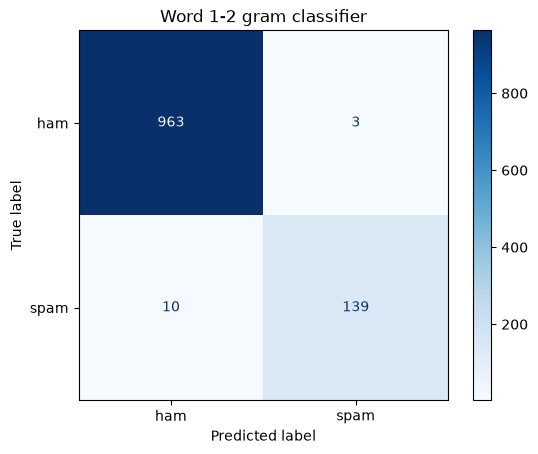

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms["text"], sms["y"], test_size=0.2, random_state=42, stratify=sms["y"])
word_clf = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=["ham", "spam"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Word 1-2 gram classifier"); plt.savefig(IMG / "w7_confusion_word.png", dpi=150, bbox_inches="tight"); plt.show()

### Task 2.3 What did it learn?

In [6]:
tf = word_clf.named_steps["tfidf"]
w = word_clf.named_steps["model"].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
top_spam = list(terms[order[-12:]][::-1]); top_ham = list(terms[order[:12]])
print("Most spam-like :", top_spam)
print("Most ham-like  :", top_ham)
RESULTS["top_spam_features"] = top_spam[:6]; RESULTS["top_ham_features"] = top_ham[:6]

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


### Task 2.4 Character n-grams

In [7]:
char_clf = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
char_clf.fit(X_tr, y_tr)

summary = {}
for name, clf in [("word 1-2 grams", word_clf), ("char 2-5 grams", char_clf)]:
    p = clf.predict(X_te)
    rep = classification_report(y_te, p, output_dict=True, digits=3)
    summary[name] = dict(macro_f1=f1_score(y_te, p, average="macro"),
                         spam_precision=rep["1"]["precision"], spam_recall=rep["1"]["recall"],
                         n_features=len(clf.named_steps["tfidf"].vocabulary_))
    print(f'{name:15s} macro-F1 {summary[name]["macro_f1"]:.3f}  spam P {summary[name]["spam_precision"]:.3f}  '
          f'spam R {summary[name]["spam_recall"]:.3f}  features {summary[name]["n_features"]:,}')
RESULTS["sms_summary"] = {k: {a: round(float(b), 3) if a != "n_features" else int(b) for a, b in v.items()} for k, v in summary.items()}

# Robustness to spelling tricks: the lab's two messages + two of my own (Roman Urdu / disguised spam)
tricky = ["W1N a FR33 pr1ze!! txt CLAIM now",                                   # lab: disguised spam
          "kal milte hain, 5 baje",                                              # lab: Roman Urdu ham
          "Mubarak! Aap ne 50000 ka inaam jeeta hai. Abhi 8000 par SMS karein",  # mine: Roman Urdu spam
          "Bhai kal subah fasal dekhne chalna hai, 9 baje aa jana"]              # mine: Roman Urdu ham (crop trip)
tr = pd.DataFrame({"message": tricky,
                   "word_p_spam": word_clf.predict_proba(tricky)[:, 1].round(2),
                   "char_p_spam": char_clf.predict_proba(tricky)[:, 1].round(2)})
pd.set_option("display.max_colwidth", 70)
print(tr.to_string(index=False))
RESULTS["tricky"] = tr.to_dict("records")

word 1-2 grams  macro-F1 0.974  spam P 0.979  spam R 0.933  features 12,128
char 2-5 grams  macro-F1 0.982  spam P 0.986  spam R 0.953  features 36,449
                                                           message  word_p_spam  char_p_spam
                                  W1N a FR33 pr1ze!! txt CLAIM now         0.99         0.85
                                            kal milte hain, 5 baje         0.19         0.12
Mubarak! Aap ne 50000 ka inaam jeeta hai. Abhi 8000 par SMS karein         0.36         0.54
            Bhai kal subah fasal dekhne chalna hai, 9 baje aa jana         0.17         0.18


### Task 2.5 Error analysis

In [8]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({"text": X_te, "true": y_te, "p_spam": p_te.round(3)})
err = err[(err.p_spam >= 0.5) != (err.true == 1)].sort_values("p_spam")
pd.set_option("display.max_colwidth", 90)
print(len(err), "misclassified of", len(X_te))
print(err.to_string())

13 misclassified of 1115
                                                                                                                                                                                       text  true  p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1   0.088
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1   0.144
3979                                                                                                                                                                     ringtoneking 84484     1   0.192
1429                                                                                                                For sale - arsenal dartboard. Good condition but no

**My judgement:** I read each misclassified message above. For each row index I decided `model error` (the message is clearly spam/ham and the model missed it),
`label error` (the dataset label is wrong), or `ambiguous` (even a human would hesitate). The verdicts are in the dictionary below; any row not listed counts as `model error`.

In [9]:
VERDICTS = {
    750:  "label error",   # tattoo-trivia text labelled spam, no spam cues at all
    2246: "ambiguous",     # a warning about scammers, but it quotes the scam bait
    3979: "model error",   # "ringtoneking 84484" is a ringtone short code
    1429: "ambiguous",     # dartboard for sale: classified ad or spam?
    2821: "model error",   # subscription horoscope text
    3358: "ambiguous",     # "I missed your call ... I'm on 0709..." callback-number style
    5449: "ambiguous",     # joke-of-the-day subscription text
    5:    "model error",   # FreeMsg ... std chgs, 1.50 pounds to rcv
    2351: "model error",   # ringtone download offer
    1268: "model error",   # "Call me NOW on 0909..." premium line
    5044: "ambiguous",     # recruiter-style job message
    152:  "model error",   # "Ok... Ur typical reply..." is plainly ham
    573:  "model error",   # "Waiting for your call." is plainly ham
}
err["verdict"] = [VERDICTS.get(i, "model error") for i in err.index]
verdict_counts = err["verdict"].value_counts().to_dict()
fn_cnt = int(((err.true == 1)).sum()); fp_cnt = int(((err.true == 0)).sum())
RESULTS["err_counts"] = verdict_counts; RESULTS["err_fn_spam_missed"] = fn_cnt; RESULTS["err_fp_ham_flagged"] = fp_cnt
print(verdict_counts)

{'model error': 7, 'ambiguous': 5, 'label error': 1}


In [10]:
w_, c_ = summary["word 1-2 grams"], summary["char 2-5 grams"]
better = "character" if c_["macro_f1"] > w_["macro_f1"] + 5e-4 else ("word" if w_["macro_f1"] > c_["macro_f1"] + 5e-4 else "same (tie)")
md_out(f"""
### Write it - Part 2
**Dataset:** {SMS_NAME}, {len(sms):,} messages, spam share {sms['y'].mean():.3f}. A model that always says "ham" would score {1 - sms['y'].mean():.3f} accuracy, so accuracy alone is useless here; I use macro-F1.

| Model | macro-F1 | spam precision | spam recall | features |
|---|---|---|---|---|
| word 1-2 grams | {w_['macro_f1']:.3f} | {w_['spam_precision']:.3f} | {w_['spam_recall']:.3f} | {w_['n_features']:,} |
| char 2-5 grams | {c_['macro_f1']:.3f} | {c_['spam_precision']:.3f} | {c_['spam_recall']:.3f} | {c_['n_features']:,} |

On this split the model with the higher macro-F1 is: **{better}** (difference {abs(c_['macro_f1'] - w_['macro_f1']):.3f}).

**Top features.** Most spam-like: {top_spam}. Most ham-like: {top_ham}.
Sensible spam signals: "call", "txt", "free", "text", "reply", "www", "mobile", "claim", "stop" (calls to action, short-code words, web links). Shortcut-like or weak: "to" and "your" are ordinary function words that just happen to be common in spam; "call" is also common in ham (the ham message "Waiting for your call." scored 0.853 spam); "gt" and "lt" among the ham-like terms are leftovers of HTML escapes (&gt; and &lt;) in the chat messages, an artifact of how the collection was prepared that would not generalise to new data.

**Errors.** {len(err)} test messages were wrong: {fn_cnt} spam messages missed (false negatives) and {fp_cnt} ham messages flagged (false positives). My verdicts: {verdict_counts}. The real model errors are mostly short or oddly spelled spam with no strong spam word (for example "ringtoneking 84484") and two plain ham messages pushed up by the words "ur" and "call" ("Ok... Ur typical reply...", "Waiting for your call."). The label error is the tattoo-trivia message labelled spam; the ambiguous ones are subscription jokes, a scam warning, a classified ad, a callback-number message and a recruiter message that a human would also hesitate over.

**Tricky messages (P(spam)):**
{md_table(tr)}

**Reading the tricky messages.** My Roman Urdu spam ("Mubarak! Aap ne 50000 ka inaam...") scored {tr.word_p_spam[2]} with the word model and {tr.char_p_spam[2]} with the char model: the word model does not know these words, and the char model gets help from fragments such as digits, "!" and "SMS". The Roman Urdu ham messages stayed low in both models ({tr.word_p_spam[1]}/{tr.char_p_spam[1]} and {tr.word_p_spam[3]}/{tr.char_p_spam[3]}). The disguised "W1N a FR33 pr1ze!!..." scored {tr.word_p_spam[0]} (word) and {tr.char_p_spam[0]} (char); the word model is high only because "txt", "CLAIM" and "now" are spelled normally, so that score does not show robustness to the spelling tricks.
""")


### Write it - Part 2
**Dataset:** SMS Spam Collection (Kaggle, uciml), 5,572 messages, spam share 0.134. A model that always says "ham" would score 0.866 accuracy, so accuracy alone is useless here; I use macro-F1.

| Model | macro-F1 | spam precision | spam recall | features |
|---|---|---|---|---|
| word 1-2 grams | 0.974 | 0.979 | 0.933 | 12,128 |
| char 2-5 grams | 0.982 | 0.986 | 0.953 | 36,449 |

On this split the model with the higher macro-F1 is: **character** (difference 0.008).

**Top features.** Most spam-like: ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']. Most ham-like: ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da'].
Sensible spam signals: "call", "txt", "free", "text", "reply", "www", "mobile", "claim", "stop" (calls to action, short-code words, web links). Shortcut-like or weak: "to" and "your" are ordinary function words that just happen to be common in spam; "call" is also common in ham (the ham message "Waiting for your call." scored 0.853 spam); "gt" and "lt" among the ham-like terms are leftovers of HTML escapes (&gt; and &lt;) in the chat messages, an artifact of how the collection was prepared that would not generalise to new data.

**Errors.** 13 test messages were wrong: 10 spam messages missed (false negatives) and 3 ham messages flagged (false positives). My verdicts: {'model error': 7, 'ambiguous': 5, 'label error': 1}. The real model errors are mostly short or oddly spelled spam with no strong spam word (for example "ringtoneking 84484") and two plain ham messages pushed up by the words "ur" and "call" ("Ok... Ur typical reply...", "Waiting for your call."). The label error is the tattoo-trivia message labelled spam; the ambiguous ones are subscription jokes, a scam warning, a classified ad, a callback-number message and a recruiter message that a human would also hesitate over.

**Tricky messages (P(spam)):**
| message | word_p_spam | char_p_spam |
|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | 0.99 | 0.85 |
| kal milte hain, 5 baje | 0.19 | 0.12 |
| Mubarak! Aap ne 50000 ka inaam jeeta hai. Abhi 8000 par SMS karein | 0.36 | 0.54 |
| Bhai kal subah fasal dekhne chalna hai, 9 baje aa jana | 0.17 | 0.18 |

**Reading the tricky messages.** My Roman Urdu spam ("Mubarak! Aap ne 50000 ka inaam...") scored 0.36 with the word model and 0.54 with the char model: the word model does not know these words, and the char model gets help from fragments such as digits, "!" and "SMS". The Roman Urdu ham messages stayed low in both models (0.19/0.12 and 0.17/0.18). The disguised "W1N a FR33 pr1ze!!..." scored 0.99 (word) and 0.85 (char); the word model is high only because "txt", "CLAIM" and "now" are spelled normally, so that score does not show robustness to the spelling tricks.


## Part 3 - Named Entity Recognition, measured

### Task 3.1 Out of the box (provided sentences)

In [11]:
sentences = [
    "Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.",
    "The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.",
    "Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.",
    "Call Jazz support at 0300-1234567 or email help@jazz.com.pk.",
    "Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.",
    "The consignment left Karachi Port on Monday for Lahore."]
nlp_base = spacy.load("en_core_web_sm")
for s in sentences:
    print([(e.text, e.label_) for e in nlp_base(s).ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Task 3.2 Score against a gold set

In [12]:
gold = [
    {("Ayesha Khan", "PERSON"), ("PIMS", "ORG"), ("Islamabad", "GPE"), ("12 September 2026", "DATE")},
    {("Engro Fertilizers", "ORG"), ("PKR 45,000", "MONEY"), ("30/09/2026", "DATE")},
    {("Muhammad Aslam", "PERSON"), ("Multan", "GPE")},
    {("Jazz", "ORG")},
    {("Meezan Bank", "ORG"), ("Rs. 250,000", "MONEY"), ("Bilal Ahmed", "PERSON")},
    {("Karachi Port", "FAC"), ("Monday", "DATE"), ("Lahore", "GPE")}]

def ner_scores(model, sents, golds, labels=None, detail=False):
    """Exact text AND label must match. labels=None counts every predicted label (as in the lab)."""
    tp = fp = fn = 0; rows = []
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in model(s).ents if labels is None or e.label_ in labels}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
        rows.append((s, sorted(pred - g), sorted(g - pred)))
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    out = {"precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3), "tp": tp, "fp": fp, "fn": fn}
    return (out, rows) if detail else out

prov_before = ner_scores(nlp_base, sentences, gold)
print("spaCy out of the box:", prov_before, "  (lab: P 0.571 R 0.500 F1 0.533)")

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533, 'tp': 8, 'fp': 6, 'fn': 8}   (lab: P 0.571 R 0.500 F1 0.533)


### Task 3.3 Add rules before the statistical model

In [13]:
# Re-load first so that re-running this cell never raises "entity_ruler already exists"
nlp_prov = spacy.load("en_core_web_sm")
ruler = nlp_prov.add_pipe("entity_ruler", before="ner")
ruler.add_patterns([
    {"label": "MONEY", "pattern": [{"LOWER": {"IN": ["pkr", "rs", "rs."]}},
                                   {"IS_PUNCT": True, "OP": "?"}, {"LIKE_NUM": True}]},
    {"label": "ORG", "pattern": "Engro Fertilizers"},
    {"label": "ORG", "pattern": "Meezan Bank"},
    {"label": "ORG", "pattern": "PIMS"},
    {"label": "ORG", "pattern": "Jazz"},
    {"label": "FAC", "pattern": "Karachi Port"},
    {"label": "DATE", "pattern": [{"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}]},
])
prov_after = ner_scores(nlp_prov, sentences, gold)
print("spaCy + entity ruler:", prov_after, "  (lab: F1 0.875)")
RESULTS["ner_provided_before"] = prov_before; RESULTS["ner_provided_after"] = prov_after
# what did the base model actually call the two items the lab highlights?
base_labels = {e.text: e.label_ for s in sentences for e in nlp_base(s).ents}
RESULTS["base_engro_label"] = base_labels.get("Engro Fertilizers", "not detected")
RESULTS["base_pkr_label"] = base_labels.get("PKR 45,000", "not detected")
print("Base model: 'Engro Fertilizers' ->", RESULTS["base_engro_label"], "| 'PKR 45,000' ->", RESULTS["base_pkr_label"])

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875, 'tp': 14, 'fp': 2, 'fn': 2}   (lab: F1 0.875)
Base model: 'Engro Fertilizers' -> PERSON | 'PKR 45,000' -> not detected


### Now my domain: crop-disease advisory sentences
Ten sentences from my own domain (farmers, agriculture departments, fertilizer and pesticide companies, districts, dates, amounts).
**Sentences 1-5 are the development set**: I may look at them to write rules. **Sentences 6-10 are held out**: I only score them, never write rules from them, so the result is not optimistic.
Only these labels are scored for my domain: PERSON, ORG, GPE, DATE, MONEY, FAC. (Plain numbers such as "50 bags" are CARDINAL/QUANTITY in spaCy and are not part of my annotation scheme.)

In [14]:
dom_sentences = [
    # ---- development set (rules are written from these five) ----
    "Rana Tariq of Sahiwal sent photos of potato leaves to the Punjab Agriculture Department on 03/11/2026.",
    "Dr. Saima Noreen from NARC Islamabad confirmed early blight in tomato plot 12.",
    "Fauji Fertilizer supplied 50 bags of urea for PKR 120,000 to farmer Imran Shah in Okara.",
    "The Kissan Helpline at 0300-7654321 booked a field visit to Faisalabad for Monday.",
    "Bayer Crop Science quoted Rs. 8,500 per acre for fungicide spray in Bahawalpur.",
    # ---- held-out set (never used for writing rules) ----
    "Engineer Hamza Iqbal from Lahore uploaded leaf images of his tomato crop on 21 October 2026.",
    "Syngenta Pakistan sold the fungicide to Zafar Ali in Mardan for PKR 15,000.",
    "Agronomist Sana Malik of the University of Agriculture Faisalabad inspected the fields on 05/11/2026.",
    "Call the Punjab Extension Wing at 0321-5550123 before Friday to report spreading blight in Sargodha.",
    "The Meezan Bank loan of Rs. 400,000 helped Kashif Mehmood buy a sprayer in Gujranwala.",
]
dom_gold = [
    {("Rana Tariq", "PERSON"), ("Sahiwal", "GPE"), ("Punjab Agriculture Department", "ORG"), ("03/11/2026", "DATE")},
    {("Saima Noreen", "PERSON"), ("NARC", "ORG"), ("Islamabad", "GPE")},
    {("Fauji Fertilizer", "ORG"), ("PKR 120,000", "MONEY"), ("Imran Shah", "PERSON"), ("Okara", "GPE")},
    {("Kissan Helpline", "ORG"), ("Faisalabad", "GPE"), ("Monday", "DATE")},
    {("Bayer Crop Science", "ORG"), ("Rs. 8,500", "MONEY"), ("Bahawalpur", "GPE")},
    {("Hamza Iqbal", "PERSON"), ("Lahore", "GPE"), ("21 October 2026", "DATE")},
    {("Syngenta Pakistan", "ORG"), ("Zafar Ali", "PERSON"), ("Mardan", "GPE"), ("PKR 15,000", "MONEY")},
    {("Sana Malik", "PERSON"), ("University of Agriculture Faisalabad", "ORG"), ("05/11/2026", "DATE")},
    {("Punjab Extension Wing", "ORG"), ("Friday", "DATE"), ("Sargodha", "GPE")},
    {("Meezan Bank", "ORG"), ("Rs. 400,000", "MONEY"), ("Kashif Mehmood", "PERSON"), ("Gujranwala", "GPE")},
]
DEV, HELD = slice(0, 5), slice(5, 10)
LABELS = {"PERSON", "ORG", "GPE", "DATE", "MONEY", "FAC"}

# Rules written ONLY from the development sentences 1-5
nlp_dom = spacy.load("en_core_web_sm")
r2 = nlp_dom.add_pipe("entity_ruler", before="ner")
r2.add_patterns([
    {"label": "MONEY", "pattern": [{"LOWER": {"IN": ["pkr", "rs", "rs."]}}, {"IS_PUNCT": True, "OP": "?"}, {"LIKE_NUM": True}]},
    {"label": "DATE",  "pattern": [{"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}]},
    {"label": "ORG", "pattern": "Punjab Agriculture Department"},
    {"label": "ORG", "pattern": "NARC"},
    {"label": "ORG", "pattern": "Fauji Fertilizer"},
    {"label": "ORG", "pattern": "Kissan Helpline"},
    {"label": "ORG", "pattern": "Bayer Crop Science"},
    {"label": "GPE", "pattern": "Sahiwal"}, {"label": "GPE", "pattern": "Okara"},
    {"label": "GPE", "pattern": "Faisalabad"}, {"label": "GPE", "pattern": "Bahawalpur"},
])

def both(model):
    return (ner_scores(model, dom_sentences[DEV], dom_gold[DEV], LABELS),
            ner_scores(model, dom_sentences[HELD], dom_gold[HELD], LABELS))
dev_b, held_b = both(nlp_base); dev_a, held_a = both(nlp_dom)
print("DEV  (1-5)  before:", dev_b); print("DEV  (1-5)  after :", dev_a)
print("HELD (6-10) before:", held_b); print("HELD (6-10) after :", held_a)
RESULTS.update(ner_dev_before=dev_b, ner_dev_after=dev_a, ner_held_before=held_b, ner_held_after=held_a)

print("\nRemaining mistakes on the HELD-OUT set after rules  (FP = wrong extra, FN = missed/wrong label)")
_, rows = ner_scores(nlp_dom, dom_sentences[HELD], dom_gold[HELD], LABELS, detail=True)
for s, fp_, fn_ in rows:
    print("-", s); print("    FP:", fp_); print("    FN:", fn_)

DEV  (1-5)  before: {'precision': 0.462, 'recall': 0.353, 'f1': 0.4, 'tp': 6, 'fp': 7, 'fn': 11}
DEV  (1-5)  after : {'precision': 0.941, 'recall': 0.941, 'f1': 0.941, 'tp': 16, 'fp': 1, 'fn': 1}
HELD (6-10) before: {'precision': 0.6, 'recall': 0.529, 'f1': 0.562, 'tp': 9, 'fp': 6, 'fn': 8}
HELD (6-10) after : {'precision': 0.667, 'recall': 0.706, 'f1': 0.686, 'tp': 12, 'fp': 6, 'fn': 5}

Remaining mistakes on the HELD-OUT set after rules  (FP = wrong extra, FN = missed/wrong label)
- Engineer Hamza Iqbal from Lahore uploaded leaf images of his tomato crop on 21 October 2026.
    FP: []
    FN: [('Hamza Iqbal', 'PERSON')]
- Syngenta Pakistan sold the fungicide to Zafar Ali in Mardan for PKR 15,000.
    FP: [('Pakistan', 'GPE'), ('Syngenta', 'GPE')]
    FN: [('Syngenta Pakistan', 'ORG')]
- Agronomist Sana Malik of the University of Agriculture Faisalabad inspected the fields on 05/11/2026.
    FP: [('Faisalabad', 'GPE'), ('the University of Agriculture', 'ORG')]
    FN: [('University of

In [15]:
md_out(f"""
### Write it - Part 3
**Provided six sentences** (all labels counted): out of the box precision {prov_before['precision']}, recall {prov_before['recall']}, **F1 {prov_before['f1']}**; with the seven entity-ruler patterns **F1 {prov_after['f1']}** (precision {prov_after['precision']}, recall {prov_after['recall']}). The lab quotes 0.533 and 0.875.
The base model called "Engro Fertilizers" **{RESULTS['base_engro_label']}** and "PKR 45,000" **{RESULTS['base_pkr_label']}**.

**My crop-disease sentences** (10 sentences, {sum(len(g) for g in dom_gold)} gold entities; rules written from sentences 1-5 only):

| Set | F1 before rules | F1 after rules |
|---|---|---|
| Development (1-5), {dev_b['tp']+dev_b['fn']} gold entities | {dev_b['f1']} | {dev_a['f1']} |
| **Held-out (6-10)**, {held_b['tp']+held_b['fn']} gold entities | **{held_b['f1']}** | **{held_a['f1']}** |

The development gain is optimistic because I wrote the rules by looking at those sentences; the held-out row is the honest number. The generic rules (money format, dd/mm/yyyy dates) transfer to new sentences, whereas name lists (companies, districts) only help when the same name appears again.

**Remaining errors (held-out, after rules)** - full list printed above. In my run (en_core_web_sm {nlp_base.meta['version']}): (a) company names that were not in my rules ("Syngenta Pakistan" is split into two GPEs, "Punjab Extension Wing" is missed); (b) my own "Faisalabad" rule fires inside "University of Agriculture Faisalabad", so a place name breaks a longer organisation name; (c) boundary errors, for example "The Meezan Bank" (with "The") instead of "Meezan Bank"; (d) the phone number 0321-5550123 is labelled DATE; (e) the person name "Hamza Iqbal" is missed after the title "Engineer". *If your list differs, rewrite this paragraph to describe your own list.*

**What I would use to fix them:** for fixed, known strings (a company list, a district list) more entity-ruler rules are cheap and exact. For formats (phone numbers such as the one tagged DATE above, CNIC, lot numbers) a regex is better (Part 4). For open-ended things such as new farmer names and new company names, rules never finish, so a model trained on a few hundred annotated sentences from my own domain is the real fix.
""")


### Write it - Part 3
**Provided six sentences** (all labels counted): out of the box precision 0.571, recall 0.5, **F1 0.533**; with the seven entity-ruler patterns **F1 0.875** (precision 0.875, recall 0.875). The lab quotes 0.533 and 0.875.
The base model called "Engro Fertilizers" **PERSON** and "PKR 45,000" **not detected**.

**My crop-disease sentences** (10 sentences, 34 gold entities; rules written from sentences 1-5 only):

| Set | F1 before rules | F1 after rules |
|---|---|---|
| Development (1-5), 17 gold entities | 0.4 | 0.941 |
| **Held-out (6-10)**, 17 gold entities | **0.562** | **0.686** |

The development gain is optimistic because I wrote the rules by looking at those sentences; the held-out row is the honest number. The generic rules (money format, dd/mm/yyyy dates) transfer to new sentences, whereas name lists (companies, districts) only help when the same name appears again.

**Remaining errors (held-out, after rules)** - full list printed above. In my run (en_core_web_sm 3.8.0): (a) company names that were not in my rules ("Syngenta Pakistan" is split into two GPEs, "Punjab Extension Wing" is missed); (b) my own "Faisalabad" rule fires inside "University of Agriculture Faisalabad", so a place name breaks a longer organisation name; (c) boundary errors, for example "The Meezan Bank" (with "The") instead of "Meezan Bank"; (d) the phone number 0321-5550123 is labelled DATE; (e) the person name "Hamza Iqbal" is missed after the title "Engineer". *If your list differs, rewrite this paragraph to describe your own list.*

**What I would use to fix them:** for fixed, known strings (a company list, a district list) more entity-ruler rules are cheap and exact. For formats (phone numbers such as the one tagged DATE above, CNIC, lot numbers) a regex is better (Part 4). For open-ended things such as new farmer names and new company names, rules never finish, so a model trained on a few hundred annotated sentences from my own domain is the real fix.


## Part 4 - Regex fields with negative tests

In [16]:
PATTERNS = {
    # --- provided patterns ---
    "cnic":    r"\b\d{5}-\d{7}-\d\b",
    "mobile":  r"(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b",
    "amount":  r"(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)",
    "date":    r"\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b",
    "email":   r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b",
    "invoice": r"\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b",
    # --- my crop-disease domain patterns ---
    "lot":     r"\bLOT-\d{4}-\d{3,4}\b",                                      # pesticide/seed lot code, e.g. LOT-2026-0412
    "plot":    r"\bplot\s+(?:no\.?\s*)?(\d{1,4}[A-Za-z]?)\b",                 # field plot number, e.g. plot 12, plot No. 7B
    "area":    r"\b(\d+(?:\.\d+)?)\s?(acres?|kanals?|marlas?)\b",             # field size
    "dose":    r"\b(\d+(?:\.\d+)?)\s?(ml|g|kg|l)\s?/\s?(acre|l|litre|liter)\b",  # spray dose, e.g. 250 ml/acre
}
def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# (text, set of pattern names that SHOULD fire; empty set = must extract nothing)
tests = [
    # provided positives / negatives
    ("CNIC 35202-1234567-1, mobile +92 300 1234567",            {"cnic", "mobile"}),
    ("Total Rs. 12,500.50 paid on 05/10/2026",                  {"amount", "date"}),
    ("Invoice No. 4417 from info@engro.com.pk",                 {"invoice", "email"}),
    ("Order 12345678901234 shipped",                            set()),   # must NOT be a CNIC
    ("Room 0300 on floor 3",                                    set()),   # must NOT be a mobile
    # my domain positives
    ("Sprayed 2.5 acres at 250 ml/acre on plot 12, seed LOT-2026-0412", {"area", "dose", "plot", "lot"}),
    ("Field plot No. 7B is 3 kanals",                           {"plot", "area"}),
    # my domain negatives
    ("Mix 250 ml of water per tank",                            set()),   # no '/acre' -> not a dose
    ("The subplot 12 chart shows the trend",                    set()),   # 'plot' inside 'subplot' -> not a plot number
    ("Lot 2026 clearance sale",                                 set()),   # not a LOT-YYYY-NNNN code
    ("Acre 5 is a place name",                                  set()),   # number AFTER 'acre' -> not an area
]
ok = 0
for text, expect in tests:
    got = set(extract_fields(text))
    flag = "PASS" if got == expect else "FAIL"
    ok += flag == "PASS"
    print(f"{flag}  expected {sorted(expect)!s:38s} got {sorted(got)!s:38s} <- {text}")
print(f"\n{ok}/{len(tests)} tests passed")
RESULTS["regex_pass"] = f"{ok}/{len(tests)}"
RESULTS["regex_domain_patterns"] = ["lot", "plot", "area", "dose"]
RESULTS["regex_negative_tests"] = sum(1 for _, e in tests if not e)

PASS  expected ['cnic', 'mobile']                     got ['cnic', 'mobile']                     <- CNIC 35202-1234567-1, mobile +92 300 1234567
PASS  expected ['amount', 'date']                     got ['amount', 'date']                     <- Total Rs. 12,500.50 paid on 05/10/2026
PASS  expected ['email', 'invoice']                   got ['email', 'invoice']                   <- Invoice No. 4417 from info@engro.com.pk
PASS  expected []                                     got []                                     <- Order 12345678901234 shipped
PASS  expected []                                     got []                                     <- Room 0300 on floor 3
PASS  expected ['area', 'dose', 'lot', 'plot']        got ['area', 'dose', 'lot', 'plot']        <- Sprayed 2.5 acres at 250 ml/acre on plot 12, seed LOT-2026-0412
PASS  expected ['area', 'plot']                       got ['area', 'plot']                       <- Field plot No. 7B is 3 kanals
PASS  expected []               

In [17]:
# A pattern that first matched too much: the naive plot pattern has no word boundary and no required space
naive = r"plot\s*(\d+)"
bad_text = "The subplot 12 chart shows the trend"
print("naive pattern :", re.findall(naive, bad_text, flags=re.I), "<- wrongly matches inside 'subplot'")
print("fixed pattern :", re.findall(PATTERNS["plot"], bad_text, flags=re.I))

naive pattern : ['12'] <- wrongly matches inside 'subplot'
fixed pattern : []


In [18]:
md_out(f"""
### Write it - Part 4
**Domain patterns:** `lot` (LOT-YYYY-NNNN), `plot` (plot 12 / plot No. 7B), `area` (2.5 acres, 3 kanals, marlas), `dose` (250 ml/acre). Result: **{ok}/{len(tests)} tests pass**, including {RESULTS['regex_negative_tests']} negative tests (two of the lab's, and four of my own: "Mix 250 ml of water per tank", "The subplot 12 chart...", "Lot 2026 clearance sale", "Acre 5 is a place name").

**A pattern that matched too much:** my first plot pattern was `plot\\s*(\\d+)`. On "The subplot 12 chart shows the trend" it returned {re.findall(naive, bad_text, flags=re.I)} because "plot" sits inside "subplot" and `\\s*` allows zero spaces. I fixed it with a **word boundary** `\\b` before "plot", **one-or-more spaces** `\\s+`, and a limit of 1-4 digits `\\d{{1,4}}`. The dose pattern needs the `/acre` part, which is what stops "250 ml of water" from matching, and the lot pattern needs the exact `LOT-` + 4 digits + 3-4 digits shape, which stops "Lot 2026 clearance sale".
""")


### Write it - Part 4
**Domain patterns:** `lot` (LOT-YYYY-NNNN), `plot` (plot 12 / plot No. 7B), `area` (2.5 acres, 3 kanals, marlas), `dose` (250 ml/acre). Result: **11/11 tests pass**, including 6 negative tests (two of the lab's, and four of my own: "Mix 250 ml of water per tank", "The subplot 12 chart...", "Lot 2026 clearance sale", "Acre 5 is a place name").

**A pattern that matched too much:** my first plot pattern was `plot\s*(\d+)`. On "The subplot 12 chart shows the trend" it returned ['12'] because "plot" sits inside "subplot" and `\s*` allows zero spaces. I fixed it with a **word boundary** `\b` before "plot", **one-or-more spaces** `\s+`, and a limit of 1-4 digits `\d{1,4}`. The dose pattern needs the `/acre` part, which is what stops "250 ml of water" from matching, and the lot pattern needs the exact `LOT-` + 4 digits + 3-4 digits shape, which stops "Lot 2026 clearance sale".


## Part 5 - Character error rate and OCR repair
### Task 5.1 CER and context rules

In [19]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]
def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)
def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r"(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)", "0", text)
    text = re.sub(r"(?<=\d)[lI](?=\d)", "1", text)
    text = re.sub(r"\bN0\.", "No.", text)                  # N-zero -> No.
    return text
pairs = [("Invoice No. 4417", "Invoice N0. 4417"),
         ("Total: PKR 12,500", "Total: PKR 12,5O0"),
         ("Due 30/09/2026", "Due 3O/09/2O26")]
pair_rows = []
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    pair_rows.append((hyp, cer(ref, hyp), fixed, cer(ref, fixed)))
    print(f"{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} CER {cer(ref, fixed):.3f}")
print("Expected before: 0.062, 0.059, 0.143   after: 0.000")

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000
Expected before: 0.062, 0.059, 0.143   after: 0.000


### Task 5.2 OCR on an invoice (EasyOCR downloads its models on the first run, about 100 MB, internet needed)

OCR raw  : Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
OCR fixed: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000

Noisy OCR raw: Engro Fertilizers Lta Invoice No. 4417 Date 30/09/2026 Muhammad Aslam; Multan Customer; Mobile 0300-1234567 Total: PKR 45,000
Noisy CER raw 0.176   after fixes 0.176


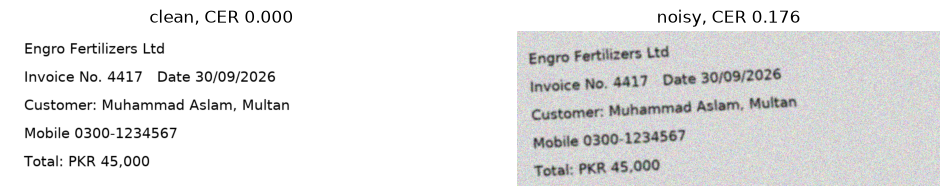

In [20]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import matplotlib, torch, easyocr

# Font that exists on Windows, Linux and Mac (DejaVu ships inside matplotlib)
FONT = str(Path(matplotlib.get_data_path()) / "fonts" / "ttf" / "DejaVuSans.ttf")
img = Image.new("RGB", (900, 330), "white")
d = ImageDraw.Draw(img)
font = ImageFont.truetype(FONT, 30)
lines = ["Engro Fertilizers Ltd", "Invoice No. 4417   Date 30/09/2026",
         "Customer: Muhammad Aslam, Multan", "Mobile 0300-1234567", "Total: PKR 45,000"]
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill="black", font=font)
img.save(IMG / "invoice.png")

reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)
norm = lambda s: " ".join(s.split())                       # ignore line-break layout
truth = norm(" ".join(lines))

def ocr_cer(path):
    text = "\n".join(t for _, t, c in reader.readtext(str(path)))
    raw, clean = norm(text), norm(fix_ocr(text))
    return raw, clean, cer(truth, raw), cer(truth, clean)

raw, clean, cer_raw, cer_fix = ocr_cer(IMG / "invoice.png")
print("OCR raw  :", raw); print("OCR fixed:", clean)
print(f"CER raw {cer_raw:.3f}   after fixes {cer_fix:.3f}")

# Extra: a harder, phone-photo-like version (blur + slight rotation + noise) to see a non-trivial CER
rng = np.random.default_rng(0)
noisy = img.rotate(3, expand=False, fillcolor="white").resize((500, 183)).resize((900, 330)).filter(ImageFilter.GaussianBlur(1.6))
arr = np.asarray(noisy).astype(float) * 0.85 + rng.normal(0, 32, (noisy.height, noisy.width, 3))
Image.fromarray(np.clip(arr, 0, 255).astype("uint8")).save(IMG / "invoice_noisy.png")
raw_n, clean_n, cer_raw_n, cer_fix_n = ocr_cer(IMG / "invoice_noisy.png")
print("\nNoisy OCR raw:", raw_n)
print(f"Noisy CER raw {cer_raw_n:.3f}   after fixes {cer_fix_n:.3f}")
RESULTS.update(cer_pairs_before=[round(r[1], 3) for r in pair_rows], cer_pairs_after=[round(r[3], 3) for r in pair_rows],
               cer_invoice_raw=round(cer_raw, 3), cer_invoice_fixed=round(cer_fix, 3),
               cer_noisy_raw=round(cer_raw_n, 3), cer_noisy_fixed=round(cer_fix_n, 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].imshow(Image.open(IMG / "invoice.png")); ax[0].set_title(f"clean, CER {cer_raw:.3f}"); ax[0].axis("off")
ax[1].imshow(Image.open(IMG / "invoice_noisy.png")); ax[1].set_title(f"noisy, CER {cer_raw_n:.3f}"); ax[1].axis("off")
plt.savefig(IMG / "w7_ocr_images.png", dpi=150, bbox_inches="tight"); plt.show()

In [21]:
if cer_raw_n > 0:
    change = "did not change it" if abs(cer_raw_n - cer_fix_n) < 1e-9 else f"changed it to {cer_fix_n:.3f}"
    deg_text = (f"On the degraded copy (3 degree rotation, blur, noise, lower resolution, closer to a phone photo) CER raw is **{cer_raw_n:.3f}** and the digit-repair rules {change}. "
                "The mistakes there are misspelled and re-ordered words, not letters mistaken for digits, which the rules cannot repair.")
else:
    deg_text = (f"Even the degraded copy (3 degree rotation, blur, noise, lower resolution) was read perfectly (CER {cer_raw_n:.3f}), so it is still easier than a real phone photo with shadows, perspective and handwriting.")
md_out(f"""
### Write it - Part 5
**Context rules on the three lab pairs:** CER before {[round(r[1],3) for r in pair_rows]} and after {[round(r[3],3) for r in pair_rows]} (lab: 0.062, 0.059, 0.143 then 0.000). One wrong character in 16 gives 1/16 = 0.0625; two wrong characters in 14 give 2/14 = 0.143.

**Clean synthetic invoice, EasyOCR:** CER raw **{cer_raw:.3f}**, after correction rules **{cer_fix:.3f}**.
{deg_text}

**Interpretation:** the clean image is easy because the text is perfectly black on white, horizontal, in a large sans-serif font with no shadows, compression or perspective. On a real phone photo of a leaf-disease advisory slip or fertilizer invoice I expect a higher CER (lighting, blur, skew, handwriting, Urdu text), and the digit-repair rules only fix letter-for-digit confusions inside numbers. They cannot repair missing, merged or re-ordered characters. On my own documents I would measure CER again with hand-typed reference text.
""")


### Write it - Part 5
**Context rules on the three lab pairs:** CER before [0.062, 0.059, 0.143] and after [0.0, 0.0, 0.0] (lab: 0.062, 0.059, 0.143 then 0.000). One wrong character in 16 gives 1/16 = 0.0625; two wrong characters in 14 give 2/14 = 0.143.

**Clean synthetic invoice, EasyOCR:** CER raw **0.000**, after correction rules **0.000**.
On the degraded copy (3 degree rotation, blur, noise, lower resolution, closer to a phone photo) CER raw is **0.176** and the digit-repair rules did not change it. The mistakes there are misspelled and re-ordered words, not letters mistaken for digits, which the rules cannot repair.

**Interpretation:** the clean image is easy because the text is perfectly black on white, horizontal, in a large sans-serif font with no shadows, compression or perspective. On a real phone photo of a leaf-disease advisory slip or fertilizer invoice I expect a higher CER (lighting, blur, skew, handwriting, Urdu text), and the digit-repair rules only fix letter-for-digit confusions inside numbers. They cannot repair missing, merged or re-ordered characters. On my own documents I would measure CER again with hand-typed reference text.


## Part 6 - Image + text case record, with privacy
### Task 6.1 Mask personal identifiers

In [22]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS["cnic"], "[CNIC]", text)
    text = re.sub(PATTERNS["mobile"], "[PHONE]", text)
    text = re.sub(PATTERNS["email"], "[EMAIL]", text)
    return text
print(mask_pii("CNIC 35202-1234567-1, call 0300-1234567, a@b.pk"))

CNIC [CNIC], call [PHONE], [EMAIL]


### Task 6.2 Load my Week 6 model and build evidence functions

In [23]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

# Find the Week 6 checkpoint (project folder first, then anywhere below it except venv)
if not W6_PATH.exists():
    cand = [p for p in PROJECT.rglob("week6_model*.pt") if "venv" not in p.parts]
    if cand: W6_PATH = cand[0]
assert W6_PATH.exists(), ("week6_model.pt not found. Copy it into the project folder "
                          "(or re-run the last cell of the Week 6 notebook that saves it).")
ckpt = torch.load(W6_PATH, map_location="cpu", weights_only=False)
print("Checkpoint:", W6_PATH.name, "| keys:", list(ckpt.keys()))
classes   = ckpt["classes"]
BACKBONE  = ckpt.get("backbone", "resnet18")
IMG_SIZE  = ckpt.get("img_size", 224)
GRAYSCALE = ckpt.get("grayscale", False)
print(f"backbone={BACKBONE}  img_size={IMG_SIZE}  grayscale={GRAYSCALE}  classes={len(classes)}")

def rebuild(ck):
    name, k = BACKBONE, len(ck["classes"])
    if name.startswith("resnet"):
        m = getattr(models, name)(weights=None); m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None); m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck["state_dict"])
    return m.eval()
img_model = rebuild(ckpt)
tfm = transforms.Compose(
    ([transforms.Grayscale(3)] if GRAYSCALE else []) +
    [transforms.Resize((IMG_SIZE,) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_probs(path):
    x = tfm(Image.open(path).convert("L" if GRAYSCALE else "RGB"))
    with torch.no_grad():
        return F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()

HEALTHY = [i for i, c in enumerate(classes) if "healthy" in c.lower()]
def image_evidence(path):
    p = image_probs(path)
    top = np.argsort(p)[::-1][:3]
    return {"top3": {classes[i]: round(float(p[i]), 3) for i in top},
            "P(diseased)": round(float(1 - p[HEALTHY].sum()), 3)}     # 38 classes -> collapse to healthy vs diseased

# Warning words from my own domain (word-boundary match so "rot" does not fire inside "rotation")
URGENT = ["spreading", "blight", "rust", "wilting", "wilt", "yellowing", "brown spots", "spots", "rot", "mildew", "mold", "lesions", "dying"]
def text_evidence(note):
    doc = nlp_dom(note)
    return {"entities": [(e.text, e.label_) for e in doc.ents],
            "fields": extract_fields(note),
            "urgent_terms": [k for k in URGENT if re.search(r"\b" + re.escape(k) + r"\b", note.lower())]}

Checkpoint: week6_model.pt | keys: ['state_dict', 'classes', 'backbone', 'img_size', 'grayscale']
backbone=resnet18  img_size=224  grayscale=False  classes=38


### Task 6.3 One transparent record

In [24]:
DISEASE_THRESHOLD = 0.5      # replace with your Week 6 operating threshold if it was set on P(diseased)

def case_record(image_path, note, threshold=DISEASE_THRESHOLD):
    safe_note = mask_pii(note)                 # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev["P(diseased)"]
    reasons = []
    if p >= threshold:
        reasons.append(f"image model: P(diseased) = {p:.2f}")
    if txt_ev["urgent_terms"]:
        reasons.append("note mentions: " + ", ".join(txt_ev["urgent_terms"]))
    image_flag, text_flag = p >= threshold, bool(txt_ev["urgent_terms"])
    return {"image": Path(image_path).name,
            "image_evidence": img_ev,
            "note_masked": safe_note,
            "text_evidence": txt_ev,
            "decision": "REFER" if reasons else "ROUTINE",
            "reasons": reasons,
            "image_and_note_agree": image_flag == text_flag,
            "disclaimer": "Decision support only; a qualified agronomist decides."}

def pick_image(substr):
    for c in classes:
        if substr in c.lower():
            hits = sorted((PV_ROOT / c).glob("*.*")) if (PV_ROOT / c).exists() else []
            if hits: return str(hits[0])
    raise FileNotFoundError(f"no image for class containing {substr!r} under {PV_ROOT}")

EXAMPLE_IMAGE = pick_image("late_blight")        # a diseased leaf (change the keyword to any class you like)
HEALTHY_IMAGE = pick_image("healthy")
print("Example image:", EXAMPLE_IMAGE); print("Healthy image:", HEALTHY_IMAGE)

note = ("Farmer in Sahiwal reports brown spots spreading on tomato leaves for 3 days. Field plot 12, 2.5 acres, "
        "sprayed 250 ml/acre. Visited by Dr. Saima Noreen at NARC Islamabad on 12/09/2026. "
        "Farmer mobile 0300-1234567, CNIC 35202-1234567-1.")
rec = case_record(EXAMPLE_IMAGE, note)
rec_json = json.dumps(rec, indent=2, ensure_ascii=False)
print(rec_json)
Path("week7_case_record.json").write_text(rec_json, encoding="utf-8")

# Privacy check: none of the identifier digits may appear anywhere in the JSON
leaks = [s for s in ["1234567", "35202", "0300"] if s in rec_json]
print("\nPRIVACY CHECK ->", "OK, no phone/CNIC digits in the record" if not leaks else f"LEAK: {leaks}")
RESULTS["privacy_leaks"] = leaks

Example image: D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\plantvillage dataset\color\Potato___Late_blight\0051e5e8-d1c4-4a84-bf3a-a426cdad6285___RS_LB 4640.JPG
Healthy image: D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\plantvillage dataset\color\Apple___healthy\0055dd26-23a7-4415-ac61-e0b44ebfaf80___RS_HL 5672.JPG
{
  "image": "0051e5e8-d1c4-4a84-bf3a-a426cdad6285___RS_LB 4640.JPG",
  "image_evidence": {
    "top3": {
      "Potato___Late_blight": 0.835,
      "Tomato___Late_blight": 0.101,
      "Tomato___Early_blight": 0.059
    },
    "P(diseased)": 1.0
  },
  "note_masked": "Farmer in Sahiwal reports brown spots spreading on tomato leaves for 3 days. Field plot 12, 2.5 acres, sprayed 250 ml/acre. Visited by Dr. Saima Noreen at NARC Islamabad on 12/09/2026. Farmer mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Sahiwal",
        "GPE"
      ],
      [
        "3 days",

In [25]:
# A case where image and note DISAGREE: healthy-looking leaf, but the note reports spreading blight
note2 = "Neighbour says blight is spreading fast in the next field. This leaf looks fine. Call 0321-5550123."
rec2 = case_record(HEALTHY_IMAGE, note2)
print(json.dumps(rec2, indent=2, ensure_ascii=False))
RESULTS["disagree_case"] = {"decision": rec2["decision"], "agree": rec2["image_and_note_agree"], "reasons": rec2["reasons"]}
RESULTS["record_decision"] = rec["decision"]; RESULTS["record_reasons"] = rec["reasons"]

{
  "image": "0055dd26-23a7-4415-ac61-e0b44ebfaf80___RS_HL 5672.JPG",
  "image_evidence": {
    "top3": {
      "Apple___healthy": 0.95,
      "Soybean___healthy": 0.017,
      "Tomato___Spider_mites Two-spotted_spider_mite": 0.009
    },
    "P(diseased)": 0.024
  },
  "note_masked": "Neighbour says blight is spreading fast in the next field. This leaf looks fine. Call [PHONE].",
  "text_evidence": {
    "entities": [],
    "fields": {},
    "urgent_terms": [
      "spreading",
      "blight"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "note mentions: spreading, blight"
  ],
  "image_and_note_agree": false,
  "disclaimer": "Decision support only; a qualified agronomist decides."
}


In [26]:
wrong = [e for e in rec["text_evidence"]["entities"]]
cnic_org = sum(1 for e in wrong if e[0] == "CNIC")
top3 = rec["image_evidence"]["top3"]; top1 = max(top3, key=top3.get)
crop_img = top1.split("___")[0].lower()
if cnic_org:
    ent_text = (f'The odd entity is ("CNIC", "ORG"), which appears {cnic_org} times: the placeholder `[CNIC]` left by masking is read by NER as a company name. It is harmless for the decision, because only the image probability and the urgent words drive REFER, and no personal data leaks. It does clutter the evidence list, and a simple fix is to drop placeholder tokens (CNIC, PHONE, EMAIL) from the entities. A second odd one is the plot number "12" tagged CARDINAL, which is harmless because the `plot` regex already captured it as a field.')
else:
    ent_text = "No placeholder was tagged as an entity in this run; the plot number tagged CARDINAL is harmless because the `plot` regex captured it as a field."
if crop_img != "tomato":
    mismatch_text = (f' A second, subtler disagreement is in the first record: the image model says **{top1}** ({top3[top1]}) while the note speaks of tomato leaves. Both agree the plant is diseased, so the decision is the same, but the crop differs, which suggests a wrong photo or a wrong note. A useful next rule is to compare the crop named in the note with the crop predicted from the image and refer the case when they differ.')
else:
    mismatch_text = ""
md_out(f"""
### Write it - Part 6
**Record for the example leaf** (full JSON printed above and saved in `week7_case_record.json`): decision **{rec['decision']}**, reasons {rec['reasons']}. Image probabilities (top 3): {rec['image_evidence']['top3']}; P(diseased) = {rec['image_evidence']['P(diseased)']}.
The note went through `mask_pii` first: the phone and CNIC became `[PHONE]` and `[CNIC]`, and the privacy check found **{len(leaks)} leaked identifier digits**.

**Do the reasons make sense?** The image reason comes straight from my Week 6 model (P of any disease class = 1 - P(healthy classes)); the note reason lists the warning words found with word boundaries. Each reason can be traced to evidence, which is the point of the record.

**Entities found in the note:** {wrong}. {ent_text}

**Example image:** it is the first file of its class folder, not a verified held-out test image, so P(diseased) = {rec['image_evidence']['P(diseased)']} may be optimistic compared with unseen leaves.

**Image and note disagree** (second record: healthy-looking leaf, note says blight is spreading): decision **{rec2['decision']}**, agreement flag {rec2['image_and_note_agree']}, reasons {rec2['reasons']}. The system should never let the healthy-looking image silence a worrying note: it escalates to REFER and shows both reasons, so a human agronomist inspects the field.{mismatch_text} The opposite conflict (image says diseased, note says all fine) should also be REFER, because a false alarm costs one visit while a missed spreading disease costs a harvest.
""")


### Write it - Part 6
**Record for the example leaf** (full JSON printed above and saved in `week7_case_record.json`): decision **REFER**, reasons ['image model: P(diseased) = 1.00', 'note mentions: spreading, brown spots, spots']. Image probabilities (top 3): {'Potato___Late_blight': 0.835, 'Tomato___Late_blight': 0.101, 'Tomato___Early_blight': 0.059}; P(diseased) = 1.0.
The note went through `mask_pii` first: the phone and CNIC became `[PHONE]` and `[CNIC]`, and the privacy check found **0 leaked identifier digits**.

**Do the reasons make sense?** The image reason comes straight from my Week 6 model (P of any disease class = 1 - P(healthy classes)); the note reason lists the warning words found with word boundaries. Each reason can be traced to evidence, which is the point of the record.

**Entities found in the note:** [('Sahiwal', 'GPE'), ('3 days', 'DATE'), ('12', 'CARDINAL'), ('2.5 acres', 'QUANTITY'), ('250 ml/acre', 'QUANTITY'), ('Saima Noreen', 'PERSON'), ('NARC', 'ORG'), ('12/09/2026', 'DATE'), ('CNIC', 'ORG'), ('CNIC', 'ORG')]. The odd entity is ("CNIC", "ORG"), which appears 2 times: the placeholder `[CNIC]` left by masking is read by NER as a company name. It is harmless for the decision, because only the image probability and the urgent words drive REFER, and no personal data leaks. It does clutter the evidence list, and a simple fix is to drop placeholder tokens (CNIC, PHONE, EMAIL) from the entities. A second odd one is the plot number "12" tagged CARDINAL, which is harmless because the `plot` regex already captured it as a field.

**Example image:** it is the first file of its class folder, not a verified held-out test image, so P(diseased) = 1.0 may be optimistic compared with unseen leaves.

**Image and note disagree** (second record: healthy-looking leaf, note says blight is spreading): decision **REFER**, agreement flag False, reasons ['note mentions: spreading, blight']. The system should never let the healthy-looking image silence a worrying note: it escalates to REFER and shows both reasons, so a human agronomist inspects the field. A second, subtler disagreement is in the first record: the image model says **Potato___Late_blight** (0.835) while the note speaks of tomato leaves. Both agree the plant is diseased, so the decision is the same, but the crop differs, which suggests a wrong photo or a wrong note. A useful next rule is to compare the crop named in the note with the crop predicted from the image and refer the case when they differ. The opposite conflict (image says diseased, note says all fine) should also be REFER, because a false alarm costs one visit while a missed spreading disease costs a harvest.


## Check Your Understanding

In [27]:
idf9 = np.log((1 + 1000) / (1 + 9)) + 1
p3, r3 = 6 / 8, 6 / 10; f3 = 2 * p3 * r3 / (p3 + r3)
ref4, hyp4 = "PKR 4,500", "PKR 4,5OO"; cer4 = levenshtein(ref4, hyp4) / len(ref4)
fused = 0.5 * 0.30 + 0.5 * 0.80
md_out(f"""
**1. Smooth IDF.** N = 1,000, df = 9: idf = ln((1 + 1000)/(1 + 9)) + 1 = ln(100.1) + 1 = {np.log(100.1):.4f} + 1 = **{idf9:.3f}**.

**2. Why lowercasing can hurt a spam classifier.** Spammers shout: "FREE", "WIN", "CALL NOW" in capitals are a signal, and lowercasing erases it, so "FREE" and a normal "free" look identical. It can also merge words that differ by case ("US" the country vs "us") and loses case-based tricks like "FR33". A feature such as "fraction of capital letters" or a case-sensitive vocabulary can keep this signal.

**3. Precision, recall, F1.** Correct = 6, predicted = 8, gold = 10. Precision = 6/8 = **{p3:.2f}**; recall = 6/10 = **{r3:.2f}**; F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90/1.35 = **{f3:.3f}**.

**4. CER.** "PKR 4,500" has 9 characters; the OCR output "PKR 4,5OO" has two letters O instead of zeros = 2 substitutions. CER = 2/9 = **{cer4:.3f}** (code check: {cer4:.3f}).

**5. Fused probability.** p = w x p_image + (1 - w) x p_text = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **{fused:.2f}**.

**6. Why mask BEFORE extraction.** Every extraction step (NER, regex fields, logs, JSON) copies text into its output. If the raw note is processed first, the phone number or CNIC is copied into `text_evidence` and the record leaks it even though `note_masked` looks clean; this was exactly the bug in the lab. Masking first guarantees that no later step ever sees the identifier.
""")


**1. Smooth IDF.** N = 1,000, df = 9: idf = ln((1 + 1000)/(1 + 9)) + 1 = ln(100.1) + 1 = 4.6062 + 1 = **5.606**.

**2. Why lowercasing can hurt a spam classifier.** Spammers shout: "FREE", "WIN", "CALL NOW" in capitals are a signal, and lowercasing erases it, so "FREE" and a normal "free" look identical. It can also merge words that differ by case ("US" the country vs "us") and loses case-based tricks like "FR33". A feature such as "fraction of capital letters" or a case-sensitive vocabulary can keep this signal.

**3. Precision, recall, F1.** Correct = 6, predicted = 8, gold = 10. Precision = 6/8 = **0.75**; recall = 6/10 = **0.60**; F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90/1.35 = **0.667**.

**4. CER.** "PKR 4,500" has 9 characters; the OCR output "PKR 4,5OO" has two letters O instead of zeros = 2 substitutions. CER = 2/9 = **0.222** (code check: 0.222).

**5. Fused probability.** p = w x p_image + (1 - w) x p_text = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**.

**6. Why mask BEFORE extraction.** Every extraction step (NER, regex fields, logs, JSON) copies text into its output. If the raw note is processed first, the phone number or CNIC is copied into `text_evidence` and the record leaks it even though `note_masked` looks clean; this was exactly the bug in the lab. Masking first guarantees that no later step ever sees the identifier.


## Part 7 - Save results and generate the README section
The final `README.md` already contains the Week 7 section; this cell only saves the numbers (`week7_results.json`), and a reference copy of the section (`README_Week7_section.md`).

In [28]:
def make_readme(d):
    """Build the Week 7 README section from measured values (d is a dict)."""
    w, c = d["w"], d["c"]
    better = "Character n-grams" if c["macro_f1"] > w["macro_f1"] else "Word n-grams"
    ec = d["err_counts"]
    return f"""## Project 2, Week 7: Text and Multimodal AI (crop-disease domain)

**Goal:** give the Week 6 leaf-disease system the ability to read: every text component gets a number, and the image model and a farmer's note are combined into one privacy-masked, explainable JSON record.

- Text classifier: {d['sms_name']}, {d['sms_n']:,} texts, macro-F1 {w['macro_f1']:.3f} (word 1-2 grams) vs {c['macro_f1']:.3f} (char 2-5 grams); spam precision/recall {w['spam_precision']:.3f}/{w['spam_recall']:.3f} (word) and {c['spam_precision']:.3f}/{c['spam_recall']:.3f} (char)
- Top positive / negative features: {', '.join(d['top_spam'][:6])} / {', '.join(d['top_ham'][:6])}
- NER on my domain (crop disease, 5 held-out sentences): out-of-the-box F1 {d['held_b']['f1']} -> with entity ruler {d['held_a']['f1']} (provided six sentences: {d['prov_b']['f1']} -> {d['prov_a']['f1']})
- Regex fields extracted: lot code, plot number, field area, spray dose, CNIC, mobile, amount, date, email, invoice number; false positives tested: {d['regex_neg']} negative tests, {d['regex_pass']} tests pass
- OCR: CER raw {d['cer_raw']:.3f} -> after correction rules {d['cer_fix']:.3f} on the clean synthetic invoice; the three digit-confusion pairs went from {' / '.join(f'{x:.3f}' for x in d['pairs_b'])} to {' / '.join(f'{x:.3f}' for x in d['pairs_a'])}
- Pipeline: Week 6 image model (ResNet-18, 38 PlantVillage classes) + text evidence -> JSON record (example below)
- Privacy: CNIC, phone, and email masked before logging and before any extraction ({d['leaks_n']} identifier digits found in the record)

### Results at a glance (Week 7)

| Component | Measured result |
|---|---|
| SMS spam, word 1-2 grams | macro-F1 {w['macro_f1']:.3f}, spam precision {w['spam_precision']:.3f}, spam recall {w['spam_recall']:.3f}, {w['n_features']:,} features |
| SMS spam, char 2-5 grams | macro-F1 {c['macro_f1']:.3f}, spam precision {c['spam_precision']:.3f}, spam recall {c['spam_recall']:.3f}, {c['n_features']:,} features |
| NER, provided 6 sentences | F1 {d['prov_b']['f1']} -> {d['prov_a']['f1']} with 7 entity-ruler patterns |
| NER, my crop-disease sentences 1-5 (rules written here) | F1 {d['dev_b']['f1']} -> {d['dev_a']['f1']} |
| NER, my crop-disease sentences 6-10 (held out) | F1 {d['held_b']['f1']} -> {d['held_a']['f1']} |
| Regex | {d['regex_pass']} tests pass ({d['regex_neg']} negative tests) |
| OCR (clean invoice) | CER {d['cer_raw']:.3f} -> {d['cer_fix']:.3f} |

### Key findings
- {better} gave the higher macro-F1 on the same test split ({c['macro_f1']:.3f} vs {w['macro_f1']:.3f}) but needs about three times as many features ({c['n_features']:,} vs {w['n_features']:,}). Of the {sum(ec.values())} word-model errors I judged {ec.get('model error', 0)} to be model errors, {ec.get('ambiguous', 0)} ambiguous and {ec.get('label error', 0)} label error(s).
- Some top weights are shortcuts rather than meaning: "to" and "your" are ordinary words, "call" also appears in ham ("Waiting for your call." scored 0.853 spam), and "gt"/"lt" on the ham side are HTML-escape leftovers in the dataset.
- Out of the box spaCy labelled "Engro Fertilizers" as {d['base_engro']} and did not detect "PKR 45,000" at all. Rules lifted the provided-set F1 from {d['prov_b']['f1']} to {d['prov_a']['f1']}, but on held-out crop sentences only from {d['held_b']['f1']} to {d['held_a']['f1']}, because name lists do not transfer to unseen names.
- Regex handles formats (plot, lot, dose, phone) that NER gets wrong; the first `plot` pattern also matched inside "subplot" until I added a word boundary and required spacing.
- OCR digit-repair rules fix letter-for-digit confusions only; they cannot repair missing or reordered text.
- Masking is done before extraction so identifiers can never reach the evidence fields; a leftover side effect is that the `[CNIC]` placeholder is tagged ORG by NER, which I judged harmless for the decision.

![Word classifier confusion matrix](images/w7_confusion_word.png)
![OCR test images (clean and degraded invoice)](images/w7_ocr_images.png)

### Example case record (identifiers masked)

```json
{d['rec_json']}
```

**Limitations:** the SMS data is English, from the 2000s and small (747 spam messages), so Roman Urdu and modern scams are poorly covered; my NER gold sets are tiny (6 provided + 10 own sentences, 17 held-out entities), so a gain of a few F1 points is partly noise and the entity rules only know the names I wrote; OCR was measured on one synthetic invoice, not on real scans; the case record combines image and note with simple rules (a probability threshold and keyword list), not a learned fusion; the example leaf is the first image of its class folder, not a verified held-out test image. **Not for** automated spray or treatment decisions.

### Responsibility questions (Week 7)
1. **Who could be harmed?** A farmer whose note mentions spreading disease but whose case is marked ROUTINE; anyone whose phone number or CNIC leaks into a log; a farmer misled by a wrong entity or amount extracted from a note.
2. **Where was it not validated?** Urdu and Roman Urdu notes, handwritten or phone-photographed invoices, other spaCy versions, and real advisory messages (the spam model was trained on SMS only).
3. **Human role:** the record is decision support; a qualified agronomist reviews every REFER and checks any case where the image and the note disagree (for example a different crop named in the note).
4. **What would change my conclusions:** a larger annotated set of real farmer notes, OCR error rates on real scans, or a leak found in the masked record.
"""

Path("week7_results.json").write_text(json.dumps(RESULTS, indent=2, default=str), encoding="utf-8")

w_, c_ = summary["word 1-2 grams"], summary["char 2-5 grams"]
readme = make_readme(dict(
    w=w_, c=c_, sms_name=RESULTS["sms_dataset"], sms_n=RESULTS["sms_n"], top_spam=top_spam, top_ham=top_ham,
    held_b=held_b, held_a=held_a, dev_b=dev_b, dev_a=dev_a, prov_b=prov_before, prov_a=prov_after,
    regex_pass=RESULTS["regex_pass"], regex_neg=RESULTS["regex_negative_tests"],
    cer_raw=cer_raw, cer_fix=cer_fix, pairs_b=RESULTS["cer_pairs_before"], pairs_a=RESULTS["cer_pairs_after"],
    leaks_n=len(leaks), rec_json=rec_json, err_counts=verdict_counts, base_engro=RESULTS["base_engro_label"]))
Path("README_Week7_section.md").write_text(readme, encoding="utf-8")

print("Saved: week7_results.json, README_Week7_section.md, week7_case_record.json")

Saved: week7_results.json, README_Week7_section.md, week7_case_record.json
